<a href="https://colab.research.google.com/github/asomers205/DS2002FA26/blob/main/notebooks/06-midterm-walmart/2026-10-30%20%E2%80%94%20Midterm%20Progress%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Setup: load and clean

Condensed from the cleaning section of `notebooks/midterm_notebook.ipynb` (same rules, same row counts), so this lab runs on its own. The data is read from the team repo pinned to commit `fd1583a` (the Oct 21 data update), not from the course repo's `data/` folder, which has an older copy with every timestamp 11 days earlier. Sales are dated by Eastern local time and landfall is **Sept 26, 2024** (Helene).

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests

# team data, pinned to the "updated data" commit (Oct 21) so it can't drift
TEAM_DATA = "https://raw.githubusercontent.com/ayanrasulova/ds2002-midterm/fd1583a/data"

raw_transactions = pd.read_csv(f"{TEAM_DATA}/walmart_transactions.csv", dtype="string", keep_default_na=False)
raw_products = pd.read_csv(f"{TEAM_DATA}/product_catalog.csv", dtype="string", keep_default_na=False)
raw_stores = pd.read_csv(f"{TEAM_DATA}/store_locations.csv", dtype="string", keep_default_na=False)

MISSING_TOKENS = {"", "NULL", "N/A", "NA", "NAN", "NONE"}

# mark blank and null-like text as missing
def normalize_missing(frame):
    cleaned = frame.copy()
    for column in cleaned.select_dtypes(include=["object", "string"]).columns:
        values = cleaned[column].astype("string").str.strip()
        cleaned[column] = values.mask(values.str.upper().isin(MISSING_TOKENS), pd.NA)
    return cleaned

# put store ids in one format
def normalize_store_id(values):
    text = values.astype("string").str.strip().str.upper()
    parts = text.str.extract(r"^FL[\s_-]?(\d{3})$", expand=False)
    return text.where(parts.isna(), "FL-" + parts)

# includes the two labels the main notebook folds in later for q3
def normalize_category(values):
    text = values.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    key = text.str.casefold().str.replace(r"[^a-z0-9]", "", regex=True)
    aliases = {
        "breakfastfoods": "Breakfast", "breakfast": "Breakfast",
        "emergencysupplies": "Emergency", "emergency": "Emergency",
        "alcoholicbeverages": "Alcohol", "alcohol": "Alcohol",
        "entertainment": "Entertainment", "gamesentertainment": "Entertainment",
        "electronics": "Electronics", "groceries": "Grocery", "grocery": "Grocery",
        "householdessentials": "Household", "household": "Household",
        "babyproducts": "Baby", "baby": "Baby",
        "health": "Health", "healthwellness": "Health", "snacks": "Snacks",
    }
    return key.map(aliases).fillna(text.str.title()).astype("string")

# remove symbols before converting to numbers
def to_number(values):
    text = values.astype("string").str.strip().str.replace(r"[$,~]", "", regex=True)
    return pd.to_numeric(text, errors="coerce")

sku_groups = {
    "PT-12": ["PT-12", "SKU#459812", "POPTART-STRAW", "PT_STRAWBERRY"],
    "WTR-24": ["WTR-24", "WATER24PK", "WTR_24PK"],
    "BATT-100": ["BATT-100", "BAT-AA4", "BATT_AA_4PK"],
    "FLASH-01": ["FLASH-01", "LED-FLASH"],
    "BEER-24": ["BEER-24", "LTBEER24"],
    "BG-MONO": ["BG-MONO", "MONOPOLY-01", "GAME-MONO"],
    "CARDS-01": ["CARDS-01", "PLAYCARD-STD"],
    "STREAM-01": ["STREAM-01", "ROKU-STD"],
    "SOUP-CAN": ["SOUP-CAN", "CNSOUP-01"],
    "BREAD-WH": ["BREAD-WH", "WHITEBREAD"],
    "PB-16": ["PB-16", "PNUTBTR-16"],
    "CNDL-EM": ["CNDL-EM", "CANDLE-EMRG"],
    "FAID-01": ["FAID-01", "FIRSTAID-KIT"],
    "CHRG-PORT": ["CHRG-PORT", "PORTCHARGER"],
    "CHIPS-VP": ["CHIPS-VP", "CHIPVARIETY"],
    "PTOWEL-6": ["PTOWEL-6", "PAPERTOWEL6"],
    "TP-12": ["TP-12", "TOILETPAPER12"],
    "DIAP-S3": ["DIAP-S3", "DIAPERS-3"],
    "BFORM-01": ["BFORM-01", "BABYFORMULA"],
    "TARP-HD": ["TARP-HD", "HDTARP-01"],
}
canonical_names = {
    "PT-12": "Strawberry Pop-Tarts", "WTR-24": "Bottled Water 24-Pack",
    "BATT-100": "AA Batteries 4-Pack", "FLASH-01": "LED Flashlight",
    "BEER-24": "Light Beer 24-Pack", "BG-MONO": "Monopoly Board Game",
    "CARDS-01": "Playing Cards", "STREAM-01": "Roku Streaming Stick",
    "SOUP-CAN": "Canned Soup", "BREAD-WH": "White Bread",
    "PB-16": "Peanut Butter", "CNDL-EM": "Emergency Candles",
    "FAID-01": "First Aid Kit", "CHRG-PORT": "Portable Phone Charger",
    "CHIPS-VP": "Chips Variety Pack", "PTOWEL-6": "Paper Towels",
    "TP-12": "Toilet Paper 12-Roll", "DIAP-S3": "Baby Diapers Size 3",
    "BFORM-01": "Infant Formula", "TARP-HD": "Heavy Duty Tarp",
}
sku_to_canonical = {alias: canonical for canonical, aliases in sku_groups.items() for alias in aliases}

products = normalize_missing(raw_products)
products["sku"] = products["sku"].str.strip().str.upper()
assert products["sku"].isin(sku_to_canonical).all(), "catalog sku without a canonical mapping"
products["canonical_sku"] = products["sku"].map(sku_to_canonical)

# transactions: dedupe, normalize, parse eastern times, quarantine negatives
transactions = normalize_missing(raw_transactions)
transactions["transaction_id"] = transactions["transaction_id"].str.strip().str.upper()
transactions = transactions.drop_duplicates(subset=["transaction_id"], keep="first").copy()
transactions["store_id"] = normalize_store_id(transactions["store_id"])
transactions["source_sku"] = transactions["sku"].str.strip().str.upper()
transactions["canonical_sku"] = transactions["source_sku"].map(sku_to_canonical).fillna(transactions["source_sku"])
transactions["product_name"] = transactions["canonical_sku"].map(canonical_names)
transactions["category"] = normalize_category(transactions["category"])
transactions["quantity"] = to_number(transactions["quantity"])
transactions["unit_price"] = to_number(transactions["unit_price"])
parsed = pd.to_datetime(transactions["timestamp"], format="mixed", errors="coerce")
transactions["timestamp_local"] = parsed.dt.tz_localize("America/New_York", ambiguous="NaT", nonexistent="NaT")
negative = transactions["quantity"].lt(0).fillna(False)
transactions_quarantined = transactions.loc[negative].copy()
transactions_clean = transactions.loc[~negative].copy()

stores = normalize_missing(raw_stores)
stores["store_id"] = normalize_store_id(stores["store_id"])
stores["latitude"] = to_number(stores["latitude"])
stores["longitude"] = to_number(stores["longitude"])
stores = stores.drop_duplicates(subset=["store_id"], keep="first").reset_index(drop=True)

# same counts as the main notebook's quality summary
assert len(transactions_clean) == 25_402 and len(transactions_quarantined) == 130
assert transactions_clean["transaction_id"].is_unique
print(f"transactions: {len(raw_transactions):,} raw -> {len(transactions_clean):,} clean "
      f"({len(raw_transactions) - len(transactions)} duplicates removed, "
      f"{len(transactions_quarantined)} negative quantities quarantined)")
print(f"transactions with no parseable timestamp (kept in totals, left off daily charts): "
      f"{transactions_clean['timestamp_local'].isna().sum():,}")
print(f"stores: {len(stores)}, categories: {transactions_clean['category'].nunique()}")

LANDFALL = pd.Timestamp("2024-09-26")
sales = transactions_clean.dropna(subset=["timestamp_local"]).copy()
sales["date"] = sales["timestamp_local"].dt.tz_localize(None).dt.normalize()

# guard against the shifted course copy, whose surge peaks on sept 14 instead
peak_day = sales.groupby("date")["quantity"].sum().idxmax()
assert peak_day == pd.Timestamp("2024-09-25"), (
    f"sales peak on {peak_day:%b %d}, this is the shifted course copy, not the team data")
print(f"data: {TEAM_DATA} (sales peak {peak_day:%b %d}, team version)")

transactions: 25,562 raw -> 25,402 clean (30 duplicates removed, 130 negative quantities quarantined)
transactions with no parseable timestamp (kept in totals, left off daily charts): 881
stores: 12, categories: 10
data: https://raw.githubusercontent.com/ayanrasulova/ds2002-midterm/fd1583a/data (sales peak Sep 25, team version)


### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [2]:
# baseline: sept 1-15. demand steps up ~1.4x on sept 16 at every store, so those days stay out
BASELINE = (pd.Timestamp("2024-09-01"), pd.Timestamp("2024-09-15"))
# surge: the 7 days before landfall, sept 19-25
SURGE = (LANDFALL - pd.Timedelta(days=7), LANDFALL - pd.Timedelta(days=1))

category_daily = sales.pivot_table(index="date", columns="category", values="quantity",
                                   aggfunc="sum", fill_value=0).astype(float)
assert category_daily.sum().sum() == sales["quantity"].sum(), "category rollup lost units"
category_daily["All categories"] = category_daily.sum(axis=1)

def window_mean(frame, window):
    return frame.loc[window[0]:window[1]].mean()

q1 = pd.DataFrame({
    "baseline_avg_units_per_day": window_mean(category_daily, BASELINE),
    "surge_avg_units_per_day": window_mean(category_daily, SURGE),
})
q1["multiple"] = q1["surge_avg_units_per_day"] / q1["baseline_avg_units_per_day"]
q1["pct_increase"] = (q1["multiple"] - 1) * 100
q1 = q1.sort_values("multiple", ascending=False)

q1_top_category = q1.drop(index="All categories").index[0]
q1_multiple = round(float(q1.loc[q1_top_category, "multiple"]), 2)
q1_baseline_window = f"{BASELINE[0]:%b %d} to {BASELINE[1]:%b %d}, 2024 ({(BASELINE[1] - BASELINE[0]).days + 1} days)"
q1_surge_window = f"{SURGE[0]:%b %d} to {SURGE[1]:%b %d}, 2024 (7 days before the {LANDFALL:%b %d} landfall)"

print("baseline window:", q1_baseline_window)
print("surge window:   ", q1_surge_window)
display(q1.round(2))
print(f"top category: {q1_top_category}, {q1.loc[q1_top_category, 'baseline_avg_units_per_day']:.1f} -> "
      f"{q1.loc[q1_top_category, 'surge_avg_units_per_day']:.1f} units/day = {q1_multiple}x "
      f"(+{q1.loc[q1_top_category, 'pct_increase']:.0f}%)")

# why sept 16-18 are not in the baseline: the step shows up at every store and in transaction counts
store_daily = sales.pivot_table(index="date", columns="store_id", values="quantity", aggfunc="sum")
step = store_daily.loc["2024-09-16":"2024-09-18"].mean() / window_mean(store_daily, BASELINE)
txn_step = sales.groupby("date").size().loc["2024-09-16":"2024-09-18"].mean() / \
    sales.groupby("date").size().loc[BASELINE[0]:BASELINE[1]].mean()
print(f"sept 16-18 vs baseline: {step.min():.2f}x to {step.max():.2f}x across all {len(step)} stores, "
      f"transaction count {txn_step:.2f}x")

# sensitivity: the 10/28 studio used sept 1-18 as the baseline
wide = window_mean(category_daily, (BASELINE[0], pd.Timestamp("2024-09-18")))
print(f"{q1_top_category} with a sept 1-18 baseline instead: "
      f"{q1.loc[q1_top_category, 'surge_avg_units_per_day'] / wide[q1_top_category]:.2f}x")

baseline window: Sep 01 to Sep 15, 2024 (15 days)
surge window:    Sep 19 to Sep 25, 2024 (7 days before the Sep 26 landfall)


,baseline_avg_units_per_day,surge_avg_units_per_day,multiple,pct_increase
category,,,,
Breakfast,73.27,376.86,5.14,414.36
Emergency,354.07,1006.43,2.84,184.25
Electronics,70.27,175.86,2.50,150.27
All categories,1103.00,2711.86,2.46,145.86
Alcohol,61.53,138.86,2.26,125.66
Entertainment,101.60,228.57,2.25,124.97
Health,42.33,95.00,2.24,124.41
Household,85.13,176.29,2.07,107.07
Grocery,171.07,306.57,1.79,79.21


top category: Breakfast, 73.3 -> 376.9 units/day = 5.14x (+414%)
sept 16-18 vs baseline: 1.25x to 1.67x across all 12 stores, transaction count 1.37x
Breakfast with a sept 1-18 baseline instead: 4.28x


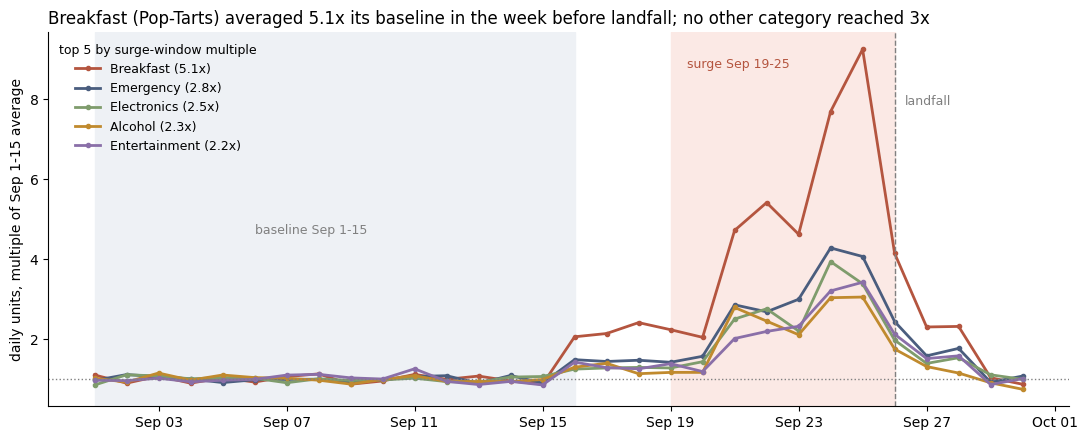

In [3]:
top5 = q1.drop(index="All categories").index[:5]
indexed = category_daily[top5] / q1.loc[top5, "baseline_avg_units_per_day"]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axvspan(BASELINE[0], BASELINE[1] + pd.Timedelta(days=1), color="#eef1f5", zorder=0)
ax.axvspan(SURGE[0], SURGE[1] + pd.Timedelta(days=1), color="#fbe9e5", zorder=0)
colors = ["#b4553f", "#4a5d7e", "#7f9c6c", "#c08a2e", "#8a6fa8"]
for category, color in zip(top5, colors):
    ax.plot(indexed.index, indexed[category], marker="o", ms=3, lw=2, color=color,
            label=f"{category} ({q1.loc[category, 'multiple']:.1f}x)")
ax.axhline(1.0, ls=":", color="gray", lw=1)
ax.axvline(LANDFALL, ls="--", color="gray", lw=1)
ymax = indexed.max().max()
ax.annotate("baseline Sep 1-15", xy=(BASELINE[0] + pd.Timedelta(days=5), ymax * 0.5), fontsize=9, color="gray")
ax.annotate("surge Sep 19-25", xy=(SURGE[0] + pd.Timedelta(hours=12), ymax * 0.95), fontsize=9, color="#b4553f")
ax.annotate("landfall", xy=(LANDFALL + pd.Timedelta(hours=8), ymax * 0.85), fontsize=9, color="gray")
runner_up = q1.drop(index="All categories").iloc[1]
ax.set_title(f"{q1_top_category} (Pop-Tarts) averaged {q1_multiple:.1f}x its baseline in the week before landfall; "
             f"no other category reached {np.ceil(runner_up['multiple']):.0f}x", loc="left", fontsize=12)
ax.set_ylabel("daily units, multiple of Sep 1-15 average")
ax.xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(frameon=False, fontsize=9, loc="upper left", title="top 5 by surge-window multiple", title_fontsize=9)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** In the 7 days before Helene's Sept 26 landfall (Sept 19–25), Breakfast, which is entirely Strawberry Pop-Tarts, sold **5.1× its Sept 1–15 daily average** (73 → 377 units/day, +414%), well ahead of Emergency supplies (2.8×) and Electronics (2.5×), while total store volume rose 2.5×.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

distinct SKUs: 45 in the catalog, 45 in transactions
canonical products: 20
largest family: PT-12 (Strawberry Pop-Tarts), 4 SKUs and 6 product-name spellings
assertion passed: 49,584 units before = 49,584 units after


,source_sku,canonical_sku,units,rank_among_45_skus
0,PT-12,PT-12,1381,8
1,POPTART-STRAW,PT-12,1300,12
2,PT_STRAWBERRY,PT-12,1262,17
3,SKU#459812,PT-12,1255,18


before: best Pop-Tart SKU PT-12 = 1,381 units, rank 8 of 45 SKUs
after:  Strawberry Pop-Tarts = 5,198 units, rank 2 of 20 products (29 units behind Bottled Water 24-Pack), 3.8x the largest SKU


,baseline_per_day,surge_per_day
source_sku,,
POPTART-STRAW,18.0,91.0
PT-12,20.4,103.3
PT_STRAWBERRY,18.1,92.4
SKU#459812,16.8,90.1
consolidated,73.3,376.9


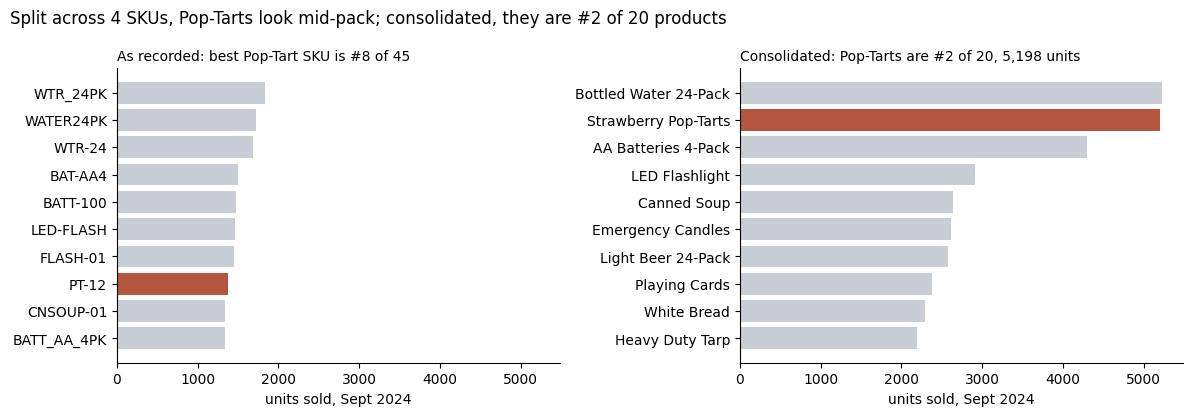

In [4]:
# what we started with vs what we ended with
n_catalog_skus = raw_products["sku"].str.strip().str.upper().nunique()
n_transaction_skus = transactions_clean["source_sku"].nunique()
n_canonical = transactions_clean["canonical_sku"].nunique()
family_sizes = transactions_clean.groupby("canonical_sku")["source_sku"].nunique().sort_values(ascending=False)
largest_family = family_sizes.index[0]
family_aliases = sku_groups[largest_family]
raw_name_spellings = raw_transactions.loc[
    raw_transactions["sku"].str.strip().str.upper().isin(family_aliases), "product_name"].nunique()

print(f"distinct SKUs: {n_catalog_skus} in the catalog, {n_transaction_skus} in transactions")
print(f"canonical products: {n_canonical}")
print(f"largest family: {largest_family} ({canonical_names[largest_family]}), "
      f"{family_sizes.iloc[0]} SKUs and {raw_name_spellings} product-name spellings")

# fragmented view (as recorded) vs consolidated view
by_source = transactions_clean.groupby("source_sku")["quantity"].sum().sort_values(ascending=False)
by_canonical = transactions_clean.groupby("canonical_sku")["quantity"].sum().sort_values(ascending=False)

# consolidation must not create or lose units, overall or inside any family
assert by_source.sum() == by_canonical.sum() == transactions_clean["quantity"].sum(), "consolidation changed unit totals"
regrouped = by_source.groupby(by_source.index.map(sku_to_canonical)).sum()
assert (regrouped - by_canonical.reindex(regrouped.index)).eq(0).all(), "a family total changed"
print(f"assertion passed: {int(by_source.sum()):,} units before = {int(by_canonical.sum()):,} units after")

family = by_source[by_source.index.isin(family_aliases)]
best_fragment = family.idxmax()
fragment_rank = list(by_source.index).index(best_fragment) + 1
family_rank = list(by_canonical.index).index(largest_family) + 1
display(pd.DataFrame({"source_sku": family.index, "canonical_sku": largest_family,
                      "units": family.values, "rank_among_45_skus": [list(by_source.index).index(s) + 1 for s in family.index]}))
print(f"before: best Pop-Tart SKU {best_fragment} = {int(family.max()):,} units, rank {fragment_rank} of {len(by_source)} SKUs")
print(f"after:  {canonical_names[largest_family]} = {int(by_canonical[largest_family]):,} units, "
      f"rank {family_rank} of {len(by_canonical)} products ({int(by_canonical.iloc[0] - by_canonical[largest_family])} "
      f"units behind {canonical_names[by_canonical.index[0]]}), {by_canonical[largest_family] / family.max():.1f}x the largest SKU")

# true daily volume, baseline vs surge
pt_daily = sales[sales["canonical_sku"] == largest_family].pivot_table(
    index="date", columns="source_sku", values="quantity", aggfunc="sum", fill_value=0)
pt_daily["consolidated"] = pt_daily.sum(axis=1)
volume = pd.DataFrame({"baseline_per_day": window_mean(pt_daily, BASELINE),
                       "surge_per_day": window_mean(pt_daily, SURGE)}).round(1)
display(volume)

# chart: top 10 as recorded vs top 10 after consolidation
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
left = by_source.head(10)[::-1]
axes[0].barh(left.index, left.values, color=["#b4553f" if s in family_aliases else "#c9cdd6" for s in left.index])
axes[0].set_title(f"As recorded: best Pop-Tart SKU is #{fragment_rank} of {len(by_source)}", fontsize=10, loc="left")
right = by_canonical.head(10)[::-1]
axes[1].barh([canonical_names[s] for s in right.index], right.values,
             color=["#b4553f" if s == largest_family else "#c9cdd6" for s in right.index])
axes[1].set_title(f"Consolidated: Pop-Tarts are #{family_rank} of {len(by_canonical)}, "
                  f"{int(by_canonical[largest_family]):,} units", fontsize=10, loc="left")
for ax in axes:
    ax.set_xlabel("units sold, Sept 2024")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
fig.suptitle(f"Split across {len(family_aliases)} SKUs, Pop-Tarts look mid-pack; consolidated, "
             f"they are #{family_rank} of {len(by_canonical)} products", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

**Q2 answer:** We started with **45 distinct SKUs** (45 in the catalog, the same 45 in transactions) and ended with **20 canonical products**. The largest family is **Strawberry Pop-Tarts (PT-12)**: 4 SKUs (`PT-12`, `SKU#459812`, `POPTART-STRAW`, `PT_STRAWBERRY`) and 6 spellings of the product name. Before consolidation the best Pop-Tart SKU sells 1,381 units and ranks **#8 of 45**, and each SKU averages only 17–20 units/day at baseline. After consolidation Pop-Tarts sell **5,198 units, #2 of 20 products**, just 29 units behind bottled water. That is 3.8× the largest single SKU, and 73 → 377 units/day across baseline and surge. The assertion confirms 49,584 units both before and after. **Business impact:** on the fragmented view, a buyer would stock Pop-Tarts as an ordinary item and spread pre-storm orders across four SKUs at about 100 units/day each. The consolidated view shows a single product that needs about 377 units/day across the state and belongs with water and batteries on the storm-prep list.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

weather: live (https://archive-api.open-meteo.com/v1/archive), 8,928 hourly rows for 12 stores
join: 360 store-days before, 360 after, merge {'both': 360, 'left_only': 0, 'right_only': 0}, units 47,897 unchanged


,n_days,max wind,min pressure,rain,max wind (spearman)
lag_days,,,,,
-3,27,-0.24,0.03,-0.62,-0.47
-2,28,-0.11,-0.06,-0.61,-0.16
-1,29,0.04,-0.13,-0.58,-0.04
0,30,0.23,-0.24,-0.30,0.34
1,29,0.58,-0.59,0.01,0.24
2,28,0.80,-0.80,0.02,0.25
3,27,0.61,-0.62,-0.06,0.24
4,26,0.42,-0.43,-0.03,0.30
5,25,0.34,-0.36,-0.10,0.19


same day (n = 30 days): wind r = +0.23, pressure r = -0.24, rain r = -0.30
best lag +2 days (n = 28 days): wind r = +0.80, pressure r = -0.80, wind spearman = +0.25


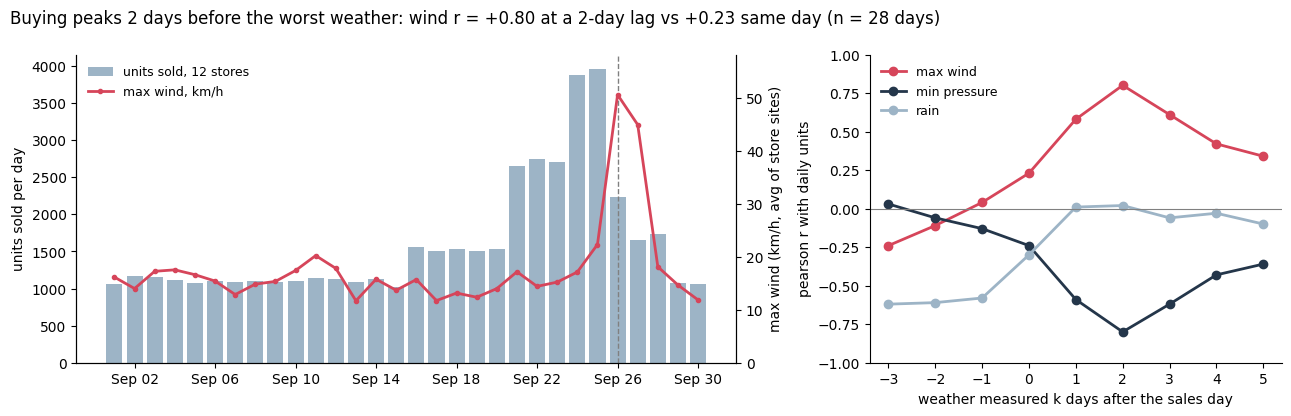

In [5]:
# --- the api call: open-meteo historical archive, free, no key, one request for all 12 stores ---
WEATHER_BASE_URL = "https://archive-api.open-meteo.com/v1/archive"
WEATHER_VARIABLES = ["precipitation", "wind_speed_10m", "pressure_msl"]
RETRY_STATUSES = {429, 500, 502, 503, 504}

def fetch_hourly_weather(coordinates, start, end, tries=3):
    params = {
        "latitude": ",".join(coordinates["latitude"].astype(str)),
        "longitude": ",".join(coordinates["longitude"].astype(str)),
        "start_date": start, "end_date": end,
        "hourly": ",".join(WEATHER_VARIABLES),
        "timezone": "GMT",  # utc on purpose, converted to eastern below
    }
    for attempt in range(1, tries + 1):
        try:
            response = requests.get(WEATHER_BASE_URL, params=params, timeout=30)
        except (requests.ConnectionError, requests.Timeout):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if response.status_code in RETRY_STATUSES and attempt < tries:
            time.sleep(2 ** attempt)
            continue
        response.raise_for_status()
        break
    locations = response.json()
    locations = [locations] if isinstance(locations, dict) else locations
    assert len(locations) == len(coordinates), "api returned a different number of locations"
    frames = []
    for store_id, latitude, location in zip(coordinates["store_id"], coordinates["latitude"], locations):
        assert abs(location["latitude"] - latitude) < 0.5, f"location order mismatch at {store_id}"
        frames.append(pd.DataFrame(location["hourly"]).assign(store_id=store_id))
    hourly = pd.concat(frames, ignore_index=True).rename(columns={"time": "time_utc"})
    hourly["time_utc"] = pd.to_datetime(hourly["time_utc"]).dt.tz_localize("UTC")
    hourly["source"] = "open-meteo"
    return hourly

# tallahassee (FL-619) has no coordinates in the store file, use the city center
store_coordinates = stores[["store_id", "latitude", "longitude"]].copy()
store_coordinates.loc[store_coordinates["store_id"].eq("FL-619") & store_coordinates["latitude"].isna(),
                      ["latitude", "longitude"]] = [30.4383, -84.2807]
assert store_coordinates[["latitude", "longitude"]].notna().all().all()

# no fallback: if this fails, q3 stops here rather than running on made-up weather
weather_hourly = fetch_hourly_weather(store_coordinates, "2024-09-01", "2024-10-01")  # +1 day covers sept 30 eastern
weather_source = "live" if weather_hourly["source"].eq("open-meteo").all() else "fallback"
print(f"weather: {weather_source} ({WEATHER_BASE_URL}), {len(weather_hourly):,} hourly rows for {len(store_coordinates)} stores")

# utc -> eastern (EDT, utc-4 in sept) before cutting days; rain is stamped at the end of its hour
weather_hourly = weather_hourly.sort_values(["store_id", "time_utc"])
weather_hourly["date"] = weather_hourly["time_utc"].dt.tz_convert("America/New_York").dt.tz_localize(None).dt.normalize()
weather_hourly["rain_in_hour"] = weather_hourly.groupby("store_id")["precipitation"].shift(-1)
weather_daily = weather_hourly.groupby(["store_id", "date"], as_index=False).agg(
    precipitation_mm=("rain_in_hour", "sum"), max_wind_kmh=("wind_speed_10m", "max"),
    min_pressure_hpa=("pressure_msl", "min"), hours=("time_utc", "size"), source=("source", "first"))
weather_daily = weather_daily[weather_daily["date"].between("2024-09-01", "2024-09-30")]
assert weather_daily["hours"].eq(24).all(), "some store-days are missing hours"

# --- the validated join: store-day sales (eastern dates) left-joined to store-day weather ---
store_day_sales = sales.groupby(["store_id", "date"], as_index=False)["quantity"].sum().rename(columns={"quantity": "units"})
joined = store_day_sales.merge(weather_daily, on=["store_id", "date"], how="left",
                               validate="one_to_one", indicator=True)
rows_before, rows_after = len(store_day_sales), len(joined)
join_rows_preserved = (rows_before == rows_after
                       and joined["units"].sum() == store_day_sales["units"].sum()
                       and joined["_merge"].eq("both").all())
assert join_rows_preserved, "join lost or duplicated rows"
print(f"join: {rows_before} store-days before, {rows_after} after, merge {joined['_merge'].value_counts().to_dict()}, "
      f"units {int(joined['units'].sum()):,} unchanged")

# --- the relationship: statewide day (units summed over stores, weather averaged over store sites) ---
WEATHER_COLUMNS = {"max_wind_kmh": "max wind", "min_pressure_hpa": "min pressure", "precipitation_mm": "rain"}
statewide = joined.groupby("date").agg(units=("units", "sum"), **{c: (c, "mean") for c in WEATHER_COLUMNS})

# lag k = weather k days after the sales day (positive k means sales move first)
def lagged_corr(k, column, method="pearson"):
    shifted = statewide[column].shift(-k)
    keep = shifted.notna()
    return statewide.loc[keep, "units"].corr(shifted[keep], method=method), int(keep.sum())

lag_table = pd.DataFrame([
    {"lag_days": k, "n_days": lagged_corr(k, "max_wind_kmh")[1],
     **{label: lagged_corr(k, column)[0] for column, label in WEATHER_COLUMNS.items()},
     "max wind (spearman)": lagged_corr(k, "max_wind_kmh", "spearman")[0]}
    for k in range(-3, 6)
]).set_index("lag_days").round(2)
display(lag_table)

best_lag = int(lag_table["max wind"].idxmax())
q3_days = int(lag_table.loc[best_lag, "n_days"])
print(f"same day (n = {lag_table.loc[0, 'n_days']} days): wind r = {lag_table.loc[0, 'max wind']:+.2f}, "
      f"pressure r = {lag_table.loc[0, 'min pressure']:+.2f}, rain r = {lag_table.loc[0, 'rain']:+.2f}")
print(f"best lag +{best_lag} days (n = {q3_days} days): wind r = {lag_table.loc[best_lag, 'max wind']:+.2f}, "
      f"pressure r = {lag_table.loc[best_lag, 'min pressure']:+.2f}, "
      f"wind spearman = {lag_table.loc[best_lag, 'max wind (spearman)']:+.2f}")

# chart: units with wind overlaid, and correlation at each lag
fig, (ax, ax_lag) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
ax.bar(statewide.index, statewide["units"], color="#9db4c6", width=0.8, label="units sold, 12 stores")
ax.set_ylabel("units sold per day")
ax2 = ax.twinx()
ax2.plot(statewide.index, statewide["max_wind_kmh"], color="#d6455a", lw=2, marker="o", ms=3, label="max wind, km/h")
ax2.set_ylim(0, statewide["max_wind_kmh"].max() * 1.15)
ax2.set_ylabel("max wind (km/h, avg of store sites)")
ax.axvline(LANDFALL, ls="--", color="gray", lw=1)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0],
          ["units sold, 12 stores", "max wind, km/h"], frameon=False, fontsize=9, loc="upper left")
for column, label in WEATHER_COLUMNS.items():
    ax_lag.plot(lag_table.index, lag_table[label], marker="o", lw=2, label=label,
                color={"max wind": "#d6455a", "min pressure": "#24364a", "rain": "#9db4c6"}[label])
ax_lag.axhline(0, color="gray", lw=0.8)
ax_lag.set_ylim(-1, 1)
ax_lag.set_xlabel("weather measured k days after the sales day")
ax_lag.set_ylabel("pearson r with daily units")
ax_lag.legend(frameon=False, fontsize=9, loc="upper left")
for axis in (ax, ax2, ax_lag):
    axis.spines["top"].set_visible(False)
ax_lag.spines["right"].set_visible(False)
fig.suptitle(f"Buying peaks {best_lag} days before the worst weather: wind r = "
             f"{lag_table.loc[best_lag, 'max wind']:+.2f} at a {best_lag}-day lag vs "
             f"{lag_table.loc[0, 'max wind']:+.2f} same day (n = {q3_days} days)", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

**Q3 answer, with its caveat:** Weather is **live** Open-Meteo archive data (one API call, 12 store sites, hourly UTC converted to Eastern before rolling up to days; no fallback). The left join kept **all 360 store-days (360 before, 360 after, every row matched, units unchanged)**. On the same day, weather barely tracks sales (wind r = +0.23, pressure r = −0.24, n = 30 days). Sales line up with the weather **two days later**: wind r = +0.80 and pressure r = −0.80 over **n = 28 days**. In the main notebook, 12 of 12 stores peaked 1–3 days before their own lowest pressure. People buy on the forecast, not on the weather outside, so stock has to land before the wind does. Rain is not a useful signal. **Caveat: n is small and it is one storm.** It is 28 statewide days from a single September, and the rank (Spearman) correlation at the same lag is only +0.25, so the 0.80 comes from Helene's few extreme days, not from a steady day-to-day relationship. Read it as a description of this storm's timing, not as a forecasting model.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** A first pass exists in the 10/28 studio notebook but not yet in `midterm_notebook.ipynb`. Every one of the 12 stores surged (2.2–2.7× in the Sept 19–25 window, 3.0–3.9× on its peak day). We see **no distance gradient** (r = −0.08 between peak multiple and miles from the Big Bend landfall point, n = 12 stores), so the current finding is "everyone surged about the same," and the outlier hunt still needs doing. Owner: **Andrew**, finishing it this weekend: move it into the main notebook, add the surge-timing comparison, and present it as a sorted bar chart/table with outliers named.

**Q5 (signal or artifact):** **Not started** in the shared notebook. Nothing queries the SQLite `daily_sales_summary`/`inventory_levels` tables for the board-games +250% claim yet. Owner: **Holden** (per the 10/23 checkpoint). This weekend: query both tables, audit the 3 Monopoly SKUs and the "Games & Entertainment" label, and check whether the +250% is category lumping or real demand. Q1's Entertainment multiple here is only 2.25×.

### Self-check

In [6]:
progress = {
    'q1_multiple': q1_multiple,                      # Breakfast (Pop-Tarts), surge Sept 19-25 vs baseline
    'q1_baseline_window': q1_baseline_window,
    'q2_canonical_products': n_canonical,
    'q3_join_rows_preserved': join_rows_preserved,
    'q3_days_in_correlation': q3_days,               # lagged correlation; same-day uses 30
    'charts_with_message_titles': 3,                 # q1 trend, q2 before/after, q3 overlay + lag
    'notebook_runs_clean': True,                     # verified with Restart and Run All
    'repo_pushed': True,                             # asomers205/DS2002FA26, notebooks/06-midterm-walmart/
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 5.14
PASS - q1_baseline_window = Sep 01 to Sep 15, 2024 (15 days)
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 28
PASS - charts_with_message_titles = 3
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

**a) Surprise:** Sales don't peak on landfall day. Statewide units peaked **Sept 24–25** (about 3,900/day) and had already fallen to 2,229 on Sept 26, when wind and pressure were at their worst. That is why the same-day weather correlation is weak and the 2-day lag is strong. We first suspected a timezone bug, because Open-Meteo returns UTC and dating sales by UTC would move 17.9% of transactions (the evening ones) to the next day. We checked three things: (1) weather is converted to `America/New_York` before cutting days, and sales are dated by `timestamp_local`; (2) the join is one-to-one, 360 → 360 store-days with units unchanged; (3) the lead shows up store by store, not only in the statewide average (12 of 12 stores peaked 1–3 days before their own lowest pressure). A one-hour or one-day timezone slip can't produce a consistent two-day lead at every store.

**b) Least confident:** the **Q1 Pop-Tarts multiple**. It depends on where the baseline ends. Sept 1–15 gives 5.1×. Sept 1–18 (what the 10/28 studio used) gives 4.3×, because demand had already stepped up about 1.4× on Sept 16 at every store. Peak-day-over-baseline gives 7.7–9.3×, and the 7.7× is the number we put in the 10/28 checkpoint. We picked Sept 1–15 because Sept 16–18 are clearly not "normal" days. But we can't yet explain the Sept 16 step, which is ten days before landfall and before Helene was named. We need to settle on one definition and say it out loud on Monday so the 5.1× and the earlier 7.7× don't look contradictory.